# Métodos constructivos: del vecino más cercano al *Iterated Greedy*

**Serie:** Metaheurísticas desde cero · Notebook 02 · Anterior: [01 · Introducción](../00-fundamentos/01-introduccion-optimizacion-combinatoria.ipynb) · Siguiente: [03 · Búsqueda local e ILS](03-busqueda-local-ils.ipynb)

## Tabla de contenido
1. Idea y formulación de un método constructivo
2. Utilidades, instancia y línea base aleatoria
3. Vecino más cercano (NN)
4. Heurísticas de inserción (más cercana, más lejana, más barata)
5. Greedy de aristas y ahorros de Clarke–Wright
6. Cota inferior: MST y 1-tree con ascenso subgradiente
7. Comparación empírica en 20 instancias
8. Complejidad: medición empírica
9. Constructivos aleatorizados (RCL / GRASP-like)
10. *Iterated Greedy*: destruir y reconstruir
11. Un constructivo para el QAP
12. Ventajas y limitaciones · Resumen · Ejercicios · Referencias

## Qué vas a aprender / Prerrequisitos

**Vas a aprender a**
- construir soluciones paso a paso con criterios voraces (*greedy*) y entender cuándo son buenos o malos;
- implementar y comparar cinco constructivos para TSP y uno para QAP;
- acotar inferiormente el óptimo (MST, 1-tree, ascenso de Held–Karp) para medir el **gap sin conocer el óptimo**;
- introducir **aleatoriedad** en un constructivo y **destrucción/reconstrucción** (*Iterated Greedy*) para pasar de una heurística de un solo disparo a una metaheurística de trayectoria.

**Prerrequisitos:** la notebook [01](../00-fundamentos/01-introduccion-optimizacion-combinatoria.ipynb) (TSP, QAP, gap, línea base aleatoria).

In [1]:
import itertools, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(2024)

## 1. Idea y formulación

Un **método constructivo** parte de una solución vacía y le añade **un componente a la vez** hasta completarla. En cada paso un criterio local (generalmente voraz) elige *qué* componente añadir y *dónde*.

**Intuición.** Es armar un viaje eligiendo siempre la siguiente parada "más conveniente" ahora, sin replanear lo ya decidido. A veces funciona sorprendentemente bien; otras, al final te obliga a un salto enorme porque las ciudades cercanas ya se agotaron.

**Formulación.** Sea $C$ el conjunto de componentes (ciudades, aristas, pares instalación–ubicación). Una solución parcial $s_k$ tiene $k$ componentes; el conjunto de candidatos factibles es $\mathcal{C}(s_k)$ y una función de *costo incremental* $g(c\mid s_k)$ evalúa añadir $c$:

$$
c_k = \arg\min_{c\in \mathcal{C}(s_k)} g(c\mid s_k),\qquad s_{k+1}=s_k\oplus c_k.
$$

```
s ← solución_vacía
mientras s no esté completa:
    C ← candidatos_factibles(s)
    c ← argmin_{c ∈ C} g(c | s)          # criterio voraz
    s ← s ⊕ c
devolver s
```

| Pros | Contras |
|---|---|
| Muy rápidos (polinomiales, a menudo $O(n^2)$) | Sin garantía de optimalidad; las malas decisiones tempranas no se corrigen |
| Deterministas y simples de implementar | Un solo resultado por instancia (sin aleatoriedad, no hay diversidad) |
| Excelentes **soluciones iniciales** para búsquedas locales | Calidad muy dependiente de la estructura del problema |
| Son óptimos para ciertos problemas (MST con Prim/Kruskal, caminos mínimos con Dijkstra) | Para TSP/QAP suelen quedar bastante por encima del óptimo |

Un contraste útil: el voraz *es exacto* para el árbol de expansión mínimo (propiedad de matroide) pero *no* para el TSP, aunque sean problemas "vecinos". La estructura del problema decide.

## 2. Utilidades, instancia y línea base aleatoria

Usamos el TSP euclídeo en el cuadrado unitario. Cada tour se **valida** como permutación con `es_permutacion`.

In [2]:
def crear_tsp(n, rng):
    pts = rng.random((n, 2))
    return pts, cdist(pts, pts)

def longitud_tour(D, tour):
    tour = np.asarray(tour)
    return D[tour, np.roll(tour, -1)].sum()

def es_permutacion(sol, n):
    sol = np.asarray(sol)
    return sol.shape == (n,) and np.array_equal(np.sort(sol), np.arange(n))

def graficar_tour(pts, tour, ax=None, titulo=""):
    ax = ax or plt.gca()
    t = np.append(tour, tour[0])
    ax.plot(pts[t, 0], pts[t, 1], "-o", ms=3, lw=1.1)
    ax.set_title(titulo, fontsize=10); ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])

def gap(c, ref):
    return 100.0 * (c - ref) / ref

N = 60
pts, D = crear_tsp(N, np.random.default_rng(10))

def tour_aleatorio(D, rng):
    return rng.permutation(len(D))

rs = np.random.default_rng(0)
L_alea = np.array([longitud_tour(D, tour_aleatorio(D, rs)) for _ in range(2000)])
print(f"Aleatorio: media={L_alea.mean():.3f}, mejor de 2000={L_alea.min():.3f}")

Aleatorio: media=29.508, mejor de 2000=24.285


## 3. Vecino más cercano (*Nearest Neighbor*, NN)

Partimos de una ciudad y repetimos: ir a la ciudad no visitada **más cercana**. Cada paso busca el mínimo en una fila: $O(n)$; en total $O(n^2)$.

```
t ← [inicio]
mientras queden ciudades:
    j ← argmin_{j ∉ t} d(último(t), j)
    t ← t + [j]
cerrar el ciclo
```

Es el constructivo más simple y deja un patrón reconocible: tramos locales buenos y **saltos largos al final**, cuando solo quedan ciudades lejanas dispersas. Su razón de aproximación en el peor caso crece como $\Theta(\log n)$ para TSP métrico (Rosenkrantz, Stearns & Lewis, 1977). Como es barato, es común correrlo **desde cada ciudad de partida** y quedarse con el mejor tour ($O(n^3)$ en total).

NN desde 0: 7.884 | NN mejor de 60 inicios: 7.556


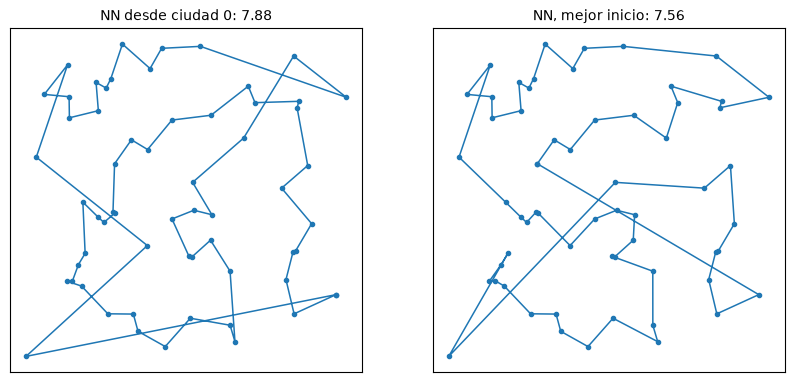

In [3]:
def vecino_mas_cercano(D, inicio=0):
    n = len(D); visitado = np.zeros(n, bool); tour = [inicio]; visitado[inicio] = True
    for _ in range(n - 1):
        d = np.where(visitado, np.inf, D[tour[-1]])
        j = int(d.argmin()); tour.append(j); visitado[j] = True
    return np.array(tour)

def nn_multiinicio(D):
    tours = [vecino_mas_cercano(D, s) for s in range(len(D))]
    L = [longitud_tour(D, t) for t in tours]
    return tours[int(np.argmin(L))]

t_nn0 = vecino_mas_cercano(D, 0); t_nnm = nn_multiinicio(D)
assert es_permutacion(t_nn0, N) and es_permutacion(t_nnm, N)
print(f"NN desde 0: {longitud_tour(D, t_nn0):.3f} | NN mejor de {N} inicios: {longitud_tour(D, t_nnm):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
graficar_tour(pts, t_nn0, axes[0], f"NN desde ciudad 0: {longitud_tour(D, t_nn0):.2f}")
graficar_tour(pts, t_nnm, axes[1], f"NN, mejor inicio: {longitud_tour(D, t_nnm):.2f}")
plt.show()

## 4. Heurísticas de inserción

En lugar de extender solo por un extremo, mantienen un **sub-tour cerrado** y en cada paso **insertan una ciudad nueva** en el lugar donde menos daño hace. Insertar $k$ entre $i$ y $j=\text{sig}(i)$ cuesta

$$
\Delta(i,k)=d_{ik}+d_{kj}-d_{ij}.
$$

Las variantes difieren en **qué ciudad $k$ se elige** (la posición siempre minimiza $\Delta$):

| Variante | Selección de la ciudad $k$ | Intuición |
|---|---|---|
| **Más cercana** | la más cercana al sub-tour actual | crecer "por contigüidad" |
| **Más barata** | la que tiene menor $\min_i\Delta(i,k)$ | minimizar el incremento ahora |
| **Más lejana** | la más lejana al sub-tour ($\max_k\min_{i\in t}d_{ik}$) | fijar primero el "esqueleto" global y rellenar después |
| **Aleatoria** | uniforme | línea base |

Para la inserción más cercana y la más barata hay garantía de razón $\le 2$ en TSP métrico (Rosenkrantz et al., 1977); en la práctica, la **más lejana** suele dar los mejores tours de las tres, porque primero traza el contorno global y luego rellena (Johnson & McGeoch, 1997). Verificaremos este orden con nuestros propios datos.

El código mantiene la distancia mínima de cada ciudad al sub-tour (`dmin`) y acumula el costo de forma **incremental**; al terminar se verifica contra la recomputación completa.

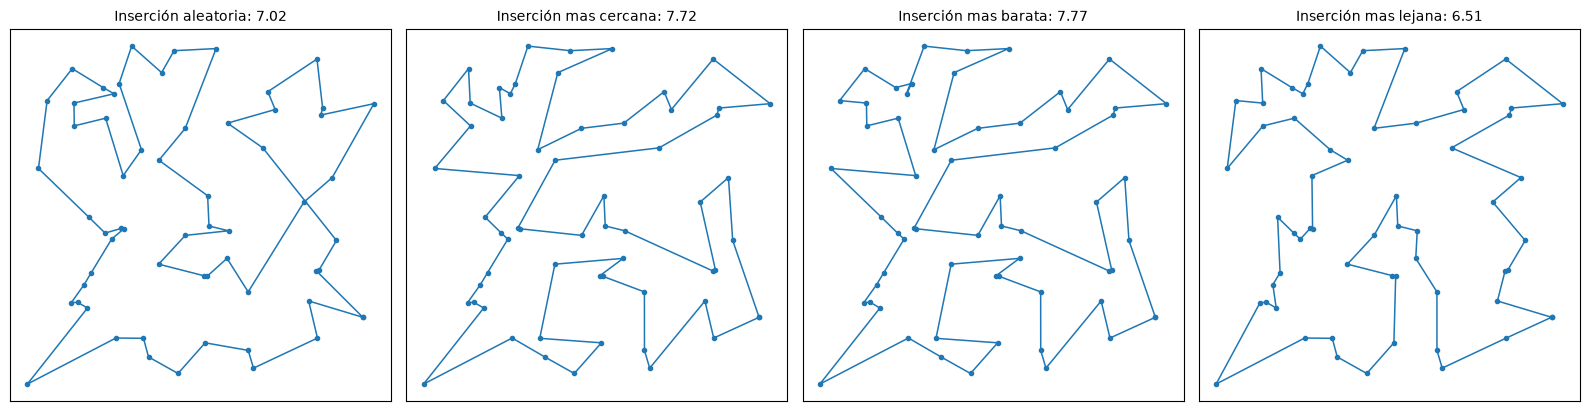

In [4]:
def insercion(D, estrategia="mas_lejana", inicio=0, rng=None):
    # estrategia in {"mas_cercana", "mas_lejana", "mas_barata", "aleatoria"}
    rng = rng or np.random.default_rng(0)
    n = len(D); fuera = np.ones(n, bool); fuera[inicio] = False
    # Sub-tour inicial de 2 ciudades: la más lejana al inicio (si es "mas_lejana"), si no la más cercana.
    if estrategia == "mas_lejana":
        j0 = int(np.argmax(np.where(fuera, D[inicio], -np.inf)))
    elif estrategia == "aleatoria":
        j0 = int(rng.choice(np.flatnonzero(fuera)))
    else:
        j0 = int(np.argmin(np.where(fuera, D[inicio], np.inf)))
    tour = [inicio, j0]; fuera[j0] = False; costo = 2 * D[inicio, j0]
    dmin = np.minimum(D[inicio], D[j0])               # distancia de cada ciudad al sub-tour
    while len(tour) < n:
        T = np.array(tour); Tn = np.roll(T, -1); base = D[T, Tn]
        K = np.flatnonzero(fuera)
        if estrategia == "mas_barata":
            C = D[np.ix_(K, T)] + D[np.ix_(K, Tn)] - base[None, :]      # (|K|, |tour|)
            pos = C.argmin(axis=1); mins = C[np.arange(len(K)), pos]
            a = int(mins.argmin()); k = int(K[a]); p = int(pos[a]); delta = mins[a]
        else:
            if estrategia == "mas_cercana":   k = int(K[np.argmin(dmin[K])])
            elif estrategia == "mas_lejana":  k = int(K[np.argmax(dmin[K])])
            else:                             k = int(rng.choice(K))
            c = D[T, k] + D[k, Tn] - base
            p = int(c.argmin()); delta = c[p]
        tour.insert(p + 1, k); fuera[k] = False; costo += delta
        dmin = np.minimum(dmin, D[k])
    tour = np.array(tour)
    assert es_permutacion(tour, n) and abs(costo - longitud_tour(D, tour)) < 1e-9   # costo incremental == recomputación
    return tour

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, est in zip(axes, ["aleatoria", "mas_cercana", "mas_barata", "mas_lejana"]):
    t = insercion(D, est, rng=np.random.default_rng(1))
    graficar_tour(pts, t, ax, f"Inserción {est.replace('_', ' ')}: {longitud_tour(D, t):.2f}")
plt.tight_layout(); plt.show()

## 5. Greedy de aristas y ahorros de Clarke–Wright

Ambos eligen **aristas** (no ciudades) en orden de conveniencia, aceptándolas solo si mantienen la estructura de "camino": ninguna ciudad con grado $>2$ y ningún ciclo prematuro. La detección de ciclos se hace con una estructura *union-find*.

### 5.1 Greedy de aristas (*greedy edge*, tipo Kruskal con grado $\le 2$)
Ordenar todas las aristas por longitud creciente y añadir cada una si ambos extremos tienen grado $<2$ y no cierra un ciclo. Tras $n-1$ aristas queda un camino hamiltoniano; se cierra.

### 5.2 Ahorros de Clarke–Wright (1964)
Pensado para ruteo de vehículos y adaptado al TSP. Se elige un **depósito** $h$ y se parte de $n-1$ viajes ida-y-vuelta $h\to i\to h$. Unir las ciudades $i$ y $j$ en un mismo viaje *ahorra*

$$
s_{ij}=d_{hi}+d_{hj}-d_{ij}.
$$

Se procesan los ahorros en orden **decreciente**, uniendo dos viajes cuando $i$ y $j$ son extremos de viajes distintos. El resultado es un camino que, cerrado con $h$, es el tour.

Ambos métodos comparten la mecánica de ensamblar un camino a partir de aristas ordenadas; solo cambia el **criterio de orden**.

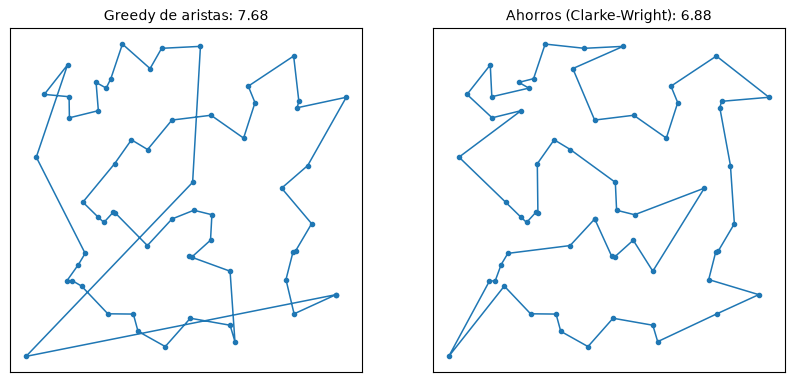

In [5]:
def ensamblar_camino(nodos, aristas_ordenadas):
    # Acepta aristas (i, j) en el orden dado si grado<2 en ambos extremos y no forman ciclo (union-find).
    # Se detiene al tener len(nodos)-1 aristas (un camino hamiltoniano). Devuelve la lista de nodos del camino.
    padre = {v: v for v in nodos}
    def raiz(x):
        while padre[x] != x:
            padre[x] = padre[padre[x]]; x = padre[x]
        return x
    grado = {v: 0 for v in nodos}; ady = {v: [] for v in nodos}; aceptadas = 0
    for i, j in aristas_ordenadas:
        if grado[i] < 2 and grado[j] < 2 and raiz(i) != raiz(j):
            padre[raiz(i)] = raiz(j); grado[i] += 1; grado[j] += 1
            ady[i].append(j); ady[j].append(i); aceptadas += 1
            if aceptadas == len(nodos) - 1:
                break
    inicio = next(v for v in nodos if grado[v] <= 1)       # extremo del camino
    camino = [inicio]; prev = None; cur = inicio
    while True:
        sig = [w for w in ady[cur] if w != prev]
        if not sig: break
        prev, cur = cur, sig[0]; camino.append(cur)
    return camino

def greedy_aristas(D):
    n = len(D); iu, ju = np.triu_indices(n, 1)
    orden = np.argsort(D[iu, ju], kind="stable")
    camino = ensamblar_camino(list(range(n)), zip(iu[orden].tolist(), ju[orden].tolist()))
    return np.array(camino)

def ahorros_cw(D, deposito=None):
    n = len(D)
    h = int(np.argmin(D.sum(axis=1))) if deposito is None else deposito       # depósito = ciudad más "central"
    nodos = [v for v in range(n) if v != h]
    iu, ju = np.triu_indices(n, 1); m = (iu != h) & (ju != h)
    iu, ju = iu[m], ju[m]
    s = D[h, iu] + D[h, ju] - D[iu, ju]
    orden = np.argsort(-s, kind="stable")
    camino = ensamblar_camino(nodos, zip(iu[orden].tolist(), ju[orden].tolist()))
    return np.array([h] + camino)

t_ge, t_cw = greedy_aristas(D), ahorros_cw(D)
assert es_permutacion(t_ge, N) and es_permutacion(t_cw, N)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
graficar_tour(pts, t_ge, axes[0], f"Greedy de aristas: {longitud_tour(D, t_ge):.2f}")
graficar_tour(pts, t_cw, axes[1], f"Ahorros (Clarke-Wright): {longitud_tour(D, t_cw):.2f}")
plt.show()

## 6. Cota inferior: MST y 1-tree con ascenso subgradiente

Para decir "a qué distancia del óptimo estoy" sin conocer el óptimo necesitamos una **cota inferior** $LB\le f^\star$. Entonces $\text{gap real}\le \text{gap vs. }LB$.

**Cota MST.** Si quitamos una arista a un tour hamiltoniano queda un árbol de expansión; luego $f^\star\ge w(\text{MST})$.

**Cota 1-tree.** Fijamos un nodo especial $0$. Un *1-tree* es un árbol de expansión de los nodos $\{1,\dots,n-1\}$ más **dos** aristas incidentes en $0$. Todo tour es un 1-tree (con grados 2), así que

$$
f^\star \ge w(\text{1-tree mínimo}) .
$$

**Ascenso de Held–Karp (1970, 1971).** Se perturban las distancias con **multiplicadores** $\pi_i$: $d'_{ij}=d_{ij}+\pi_i+\pi_j$. Como todo tour usa exactamente dos aristas por nodo, el costo de un tour solo cambia en $2\sum_i\pi_i$ y por lo tanto, para *cualquier* $\pi$,

$$
f^\star \;\ge\; L(\pi)=w_{\pi}(\text{1-tree mínimo})-2\sum_i\pi_i .
$$

Maximizar $L(\pi)$ (función cóncava) mediante **subgradiente** con $g_i=\deg_i-2$:

$$
\pi \leftarrow \pi+\theta\,g,\qquad \theta=\alpha\,\frac{UB-L(\pi)}{\lVert g\rVert^2},
$$

con $UB$ una cota superior (cualquier tour) y $\alpha$ decreciente. Si el 1-tree resultante es un tour, es óptimo. En instancias euclídeas aleatorias la cota resultante suele quedar muy cerca del óptimo (Johnson & McGeoch, 1997, la usan como vara de comparación). Verificamos la **validez** de la cota contra el óptimo exacto en una instancia chica.

In [6]:
def prim_mst(W):
    # MST por Prim O(n^2) sobre matriz densa W. Devuelve (aristas, peso total).
    n = len(W); en = np.zeros(n, bool); en[0] = True
    dist = W[0].copy(); padre = np.zeros(n, int); aristas = []; total = 0.0
    for _ in range(n - 1):
        j = int(np.where(en, np.inf, dist).argmin())
        aristas.append((int(padre[j]), j)); total += dist[j]; en[j] = True
        mejora = (W[j] < dist) & ~en
        dist[mejora] = W[j][mejora]; padre[mejora] = j
    return aristas, total

def un_arbol(W):
    # 1-tree mínimo: MST sobre nodos 1..n-1 + las 2 aristas más baratas desde el nodo 0. Devuelve (peso, grados).
    n = len(W); ar, peso = prim_mst(W[1:, 1:])
    grado = np.zeros(n)
    for a, b in ar:
        grado[a + 1] += 1; grado[b + 1] += 1
    dos = np.argsort(W[0, 1:])[:2] + 1
    peso += W[0, dos].sum(); grado[0] = 2; grado[dos] += 1
    return peso, grado

def cota_1tree(D, UB, iters=120, alpha0=2.0):
    # Ascenso subgradiente de Held-Karp. Devuelve (cota_final, cota_1tree_simple).
    n = len(D); pi = np.zeros(n); mejor = -np.inf; alpha = alpha0; simple = None
    for it in range(iters):
        W = D + pi[:, None] + pi[None, :]
        peso, grado = un_arbol(W)
        L = peso - 2 * pi.sum()
        if simple is None: simple = L
        mejor = max(mejor, L)
        g = grado - 2
        if not g.any(): break                       # el 1-tree es un tour => óptimo
        pi = pi + alpha * (UB - L) / (g @ g) * g
        alpha *= 0.97
    return mejor, simple

def held_karp(D):
    # Óptimo exacto por DP (solo para n pequeño; verificación de la cota)
    n = len(D); m = n - 1; dp = np.full((1 << m, m), np.inf)
    for j in range(m): dp[1 << j, j] = D[0, j + 1]
    for S in range(1, 1 << m):
        for j in range(m):
            if (S >> j) & 1 and S != (1 << j):
                dp[S, j] = (dp[S ^ (1 << j)] + D[1:, j + 1]).min()
    return (dp[(1 << m) - 1] + D[1:, 0]).min()

# Verificación de validez: LB <= óptimo exacto en 5 instancias n=12
print(f"{'inst':>4} {'MST':>8} {'1-tree':>8} {'HK-ascenso':>11} {'óptimo':>8}   (LB <= óptimo debe cumplirse)")
for s in range(5):
    _, Dn = crear_tsp(12, np.random.default_rng(300 + s))
    opt = held_karp(Dn); ub = longitud_tour(Dn, insercion(Dn, "mas_lejana"))
    lb, lb1 = cota_1tree(Dn, ub)
    mst = prim_mst(Dn)[1]
    assert mst <= opt + 1e-9 and lb1 <= opt + 1e-9 and lb <= opt + 1e-9
    print(f"{s:>4} {mst:8.4f} {lb1:8.4f} {lb:11.4f} {opt:8.4f}")

inst      MST   1-tree  HK-ascenso   óptimo   (LB <= óptimo debe cumplirse)
   0   2.1301   2.4239      3.1389   3.1389
   1   2.6881   2.9135      3.3528   3.3528


   2   2.1998   2.4176      3.2890   3.2890


   3   2.2295   2.5177      2.9601   2.9601
   4   1.8203   2.2882      2.7556   2.7556


La jerarquía MST $\le$ 1-tree $\le$ ascenso $\le$ óptimo se cumple en las cinco instancias (los `assert` fallarían si no). Ahora la cota de la instancia de trabajo ($n=60$), con la cota superior dada por el mejor constructivo hasta ahora. Esto fija la vara contra la que mediremos todo lo demás.

In [7]:
UB = min(longitud_tour(D, t) for t in [t_nnm, t_ge, t_cw, insercion(D, "mas_lejana"), insercion(D, "mas_barata")])
lb, lb_simple = cota_1tree(D, UB)
mst_w = prim_mst(D)[1]
print(f"n={N}: MST={mst_w:.3f} | 1-tree={lb_simple:.3f} | cota de Held-Karp={lb:.3f} | mejor tour constructivo={UB:.3f}")
print(f"gap máximo posible del mejor constructivo respecto del óptimo: <= {gap(UB, lb):.2f} %")

n=60: MST=5.299 | 1-tree=5.458 | cota de Held-Karp=6.241 | mejor tour constructivo=6.510
gap máximo posible del mejor constructivo respecto del óptimo: <= 4.30 %


## 7. Comparación empírica en 20 instancias

Evaluamos cada constructivo en 20 instancias aleatorias de $n=60$ y medimos el **gap respecto a la cota de Held–Karp** (techo del gap real) y el tiempo. La línea base es un tour aleatorio.

Gap (%) respecto a la cota de Held-Karp (n=60, 20 instancias)
                         gap_medio  gap_desv  gap_min  gap_max  tiempo_ms
metodo                                                                   
Aleatorio                   422.56     34.90   349.49   470.67       0.02
NN (inicio 0)                22.58      8.19     9.20    36.87       0.11
NN (mejor de n inicios)      12.08      4.41     4.90    20.67      12.58
Inserción más cercana        22.43      4.51    12.65    29.58       1.84
Inserción más barata         18.94      3.84     8.72    28.67       4.70
Inserción más lejana          7.76      3.01     3.14    14.69       2.02
Greedy de aristas            17.20      7.45     6.29    30.21       0.53
Ahorros (C-W)                 9.24      3.25     4.80    14.67       0.74


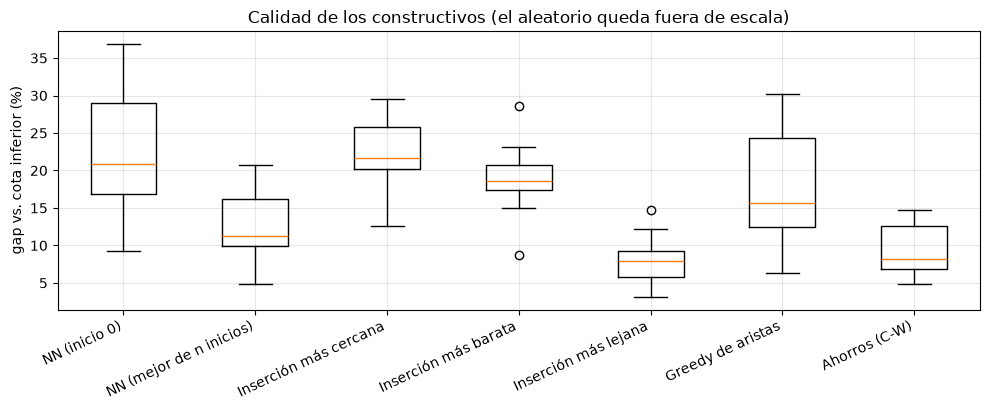

In [8]:
metodos = {
    "Aleatorio":               lambda D, r: tour_aleatorio(D, r),
    "NN (inicio 0)":           lambda D, r: vecino_mas_cercano(D, 0),
    "NN (mejor de n inicios)": lambda D, r: nn_multiinicio(D),
    "Inserción más cercana":   lambda D, r: insercion(D, "mas_cercana"),
    "Inserción más barata":    lambda D, r: insercion(D, "mas_barata"),
    "Inserción más lejana":    lambda D, r: insercion(D, "mas_lejana"),
    "Greedy de aristas":       lambda D, r: greedy_aristas(D),
    "Ahorros (C-W)":           lambda D, r: ahorros_cw(D),
}
NINST = 20
filas = []
for s in range(NINST):
    p_s, D_s = crear_tsp(60, np.random.default_rng(1000 + s)); r_s = np.random.default_rng(s)
    longs, tiempos = {}, {}
    for nombre, f in metodos.items():
        t0 = time.perf_counter(); t = f(D_s, r_s); tiempos[nombre] = time.perf_counter() - t0
        assert es_permutacion(t, 60); longs[nombre] = longitud_tour(D_s, t)
    lb_s, _ = cota_1tree(D_s, min(v for k, v in longs.items() if k != "Aleatorio"))
    for nombre in metodos:
        filas.append(dict(instancia=s, metodo=nombre, gap=gap(longs[nombre], lb_s), tiempo_ms=1e3 * tiempos[nombre]))
df = pd.DataFrame(filas)
resumen = df.groupby("metodo", sort=False).agg(gap_medio=("gap", "mean"), gap_desv=("gap", "std"), gap_min=("gap", "min"),
                                                gap_max=("gap", "max"), tiempo_ms=("tiempo_ms", "mean")).round(2)
print("Gap (%) respecto a la cota de Held-Karp (n=60, 20 instancias)")
print(resumen.to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
orden = [m for m in metodos if m != "Aleatorio"]
ax.boxplot([df[df.metodo == m].gap for m in orden], tick_labels=orden)
ax.set_ylabel("gap vs. cota inferior (%)"); ax.set_title("Calidad de los constructivos (el aleatorio queda fuera de escala)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

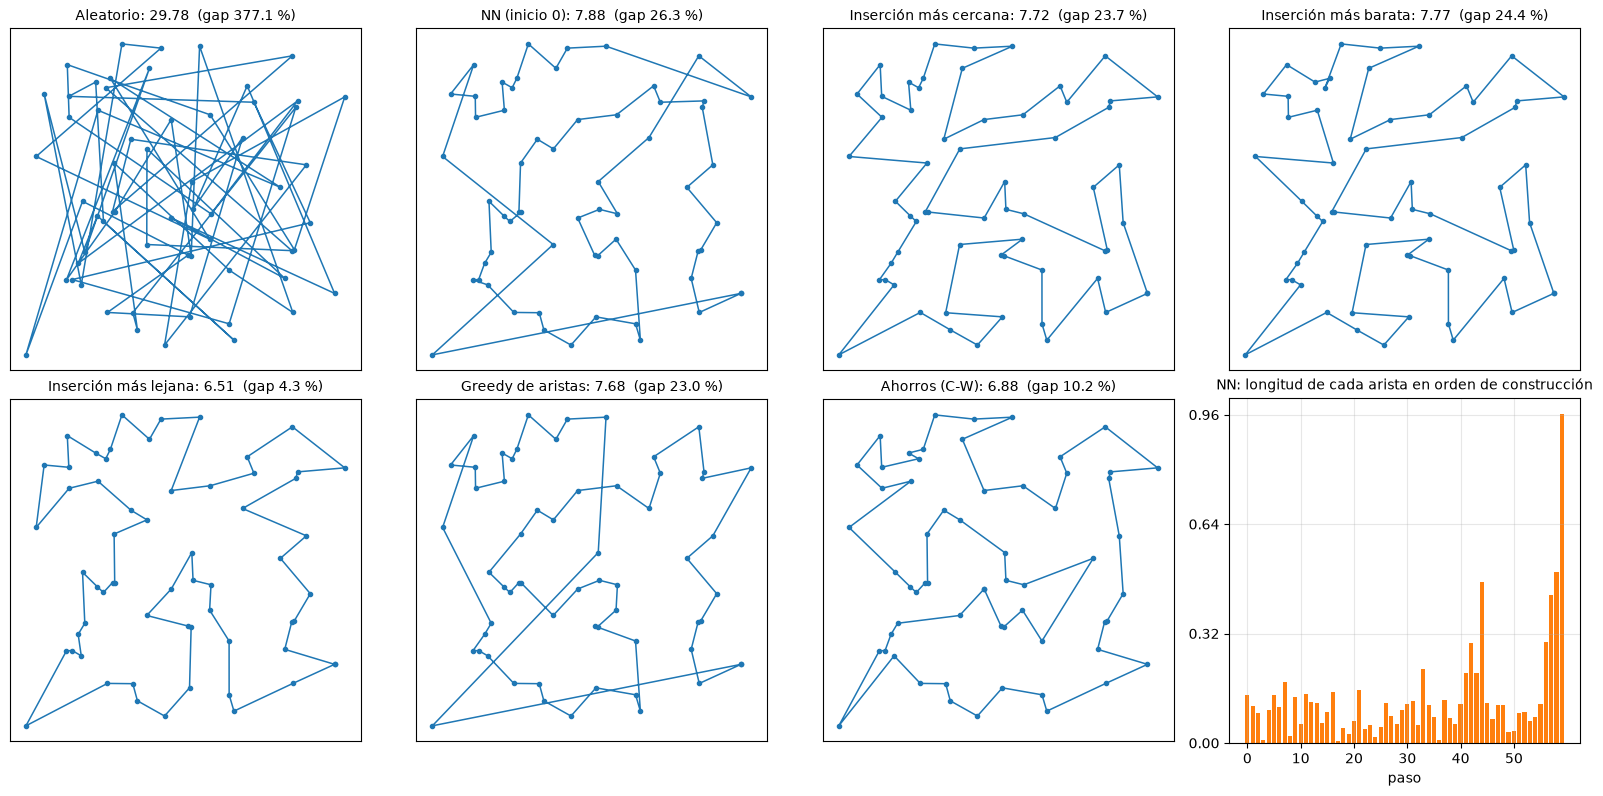

NN: arista media = 0.131; las 5 más largas ocurren en los pasos [44 56 57 58 59] (de 60)


In [9]:
# Los seis constructivos sobre la misma instancia (n=60) y el perfil de longitudes de arista de NN
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
lista = [("Aleatorio", tour_aleatorio(D, np.random.default_rng(3))), ("NN (inicio 0)", t_nn0), ("Inserción más cercana", insercion(D, "mas_cercana")),
         ("Inserción más barata", insercion(D, "mas_barata")), ("Inserción más lejana", insercion(D, "mas_lejana")),
         ("Greedy de aristas", t_ge), ("Ahorros (C-W)", t_cw)]
for ax, (nombre, t) in zip(axes.ravel(), lista):
    graficar_tour(pts, t, ax, f"{nombre}: {longitud_tour(D, t):.2f}  (gap {gap(longitud_tour(D, t), lb):.1f} %)")
aristas_nn = D[t_nn0, np.roll(t_nn0, -1)]
axes.ravel()[-1].bar(range(N), aristas_nn, color="C1"); axes.ravel()[-1].set_title("NN: longitud de cada arista en orden de construcción", fontsize=10)
axes.ravel()[-1].set_xlabel("paso"); axes.ravel()[-1].set_xticks(range(0, N, 10)); axes.ravel()[-1].set_yticks(np.round(np.linspace(0, aristas_nn.max(), 4), 2)); axes.ravel()[-1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
print(f"NN: arista media = {aristas_nn.mean():.3f}; las 5 más largas ocurren en los pasos {np.sort(np.argsort(aristas_nn)[-5:])} (de {N})")

**Lectura de la tabla** (cifras impresas arriba; la ordenación es la de esta corrida con 20 instancias):

- Todos los constructivos *inteligentes* quedan a distancia de un orden de magnitud menor que el tour aleatorio.
- La **inserción más lejana** y los **ahorros de Clarke–Wright** son los mejores de un solo disparo; NN multi-inicio queda en tercer lugar. El **greedy de aristas**, la **inserción más barata** y la **más cercana** quedan por detrás, y NN desde un único inicio es de los peores. Es el patrón que reporta la literatura empírica (Johnson & McGeoch, 1997): primero trazar el esqueleto global (más lejana) o juntar lo que más ahorra (ahorros) supera a "ser voraz con lo local".
- **Costo vs. calidad:** los métodos más rápidos (NN, ahorros, greedy) tardan fracciones de milisegundo; la inserción más barata es de las más lentas y *no* es de las mejores: "más caro" no implica "mejor".
- La dispersión entre instancias es grande (desviaciones de varios puntos porcentuales y rangos amplios): un único tour no sirve para comparar métodos; hay que usar **varias instancias**.
- NN lo vemos en la figura: sus aristas más largas aparecen casi todas al final de la construcción (impreso arriba), cuando solo quedan ciudades dispersas.

Recuerda que el gap es contra una **cota**: el gap real al óptimo es *menor o igual* que el mostrado.

## 8. Complejidad: medición empírica

Teóricamente (implementaciones directas como las de arriba):

| Método | Tiempo | Comentario |
|---|---|---|
| NN | $O(n^2)$ | una fila por paso |
| Inserción más cercana / más lejana | $O(n^2)$ | $O(n)$ por paso para actualizar `dmin` y buscar la posición |
| Inserción más barata | $O(n^3)$ | recalcula el mejor $\Delta$ de todas las ciudades en cada paso (con colas de prioridad baja a $O(n^2\log n)$) |
| Greedy de aristas / Ahorros | $O(n^2\log n)$ | ordenar $\Theta(n^2)$ aristas |

Verificamos las pendientes en escala log–log para $n=100,\dots,800$ (la pendiente de la recta es el exponente efectivo; hay constantes y efectos de vectorización con NumPy).

NN (inicio 0)            tiempos (s): [0.0005 0.0003 0.001  0.003 ]  pendiente log-log = 0.96
Inserción más lejana     tiempos (s): [0.0016 0.0037 0.0103 0.0354]  pendiente log-log = 1.49
Inserción más barata     tiempos (s): [0.0042 0.022  0.1517 0.9628]  pendiente log-log = 2.63
Greedy de aristas        tiempos (s): [0.0007 0.0031 0.0221 0.0611]  pendiente log-log = 2.20
Ahorros (C-W)            tiempos (s): [0.0008 0.0036 0.0211 0.0712]  pendiente log-log = 2.21


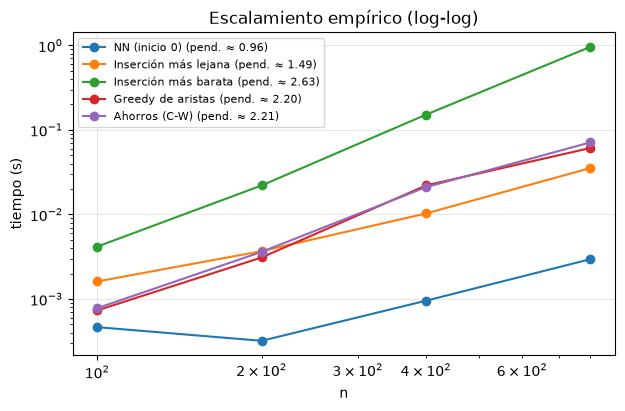

In [10]:
ns = [100, 200, 400, 800]
tiempos = {m: [] for m in ["NN (inicio 0)", "Inserción más lejana", "Inserción más barata", "Greedy de aristas", "Ahorros (C-W)"]}
for n_ in ns:
    _, D_ = crear_tsp(n_, np.random.default_rng(n_))
    for m in tiempos:
        mejor_t = np.inf
        for _ in range(2):                       # mejor de 2 repeticiones para reducir el ruido
            t0 = time.perf_counter(); metodos[m](D_, None); mejor_t = min(mejor_t, time.perf_counter() - t0)
        tiempos[m].append(mejor_t)
fig, ax = plt.subplots(figsize=(7, 4.2))
for m, v in tiempos.items():
    pend = np.polyfit(np.log(ns), np.log(v), 1)[0]
    print(f"{m:<24} tiempos (s): {np.round(v, 4)}  pendiente log-log = {pend:.2f}")
    ax.loglog(ns, v, "o-", label=f"{m} (pend. ≈ {pend:.2f})")
ax.set_xlabel("n"); ax.set_ylabel("tiempo (s)"); ax.set_title("Escalamiento empírico (log-log)"); ax.legend(fontsize=8); plt.show()

Las pendientes empíricas confirman el orden de crecimiento: la inserción más barata (naive, $O(n^3)$) se dispara y es la que más pendiente muestra, mientras que NN y la inserción más lejana quedan con pendiente bastante menor. En NN la pendiente medida es <2 porque a estos tamaños domina el costo fijo del bucle en Python ($n$ iteraciones con operaciones vectorizadas de longitud $n$), y el término $n^2$ de las operaciones NumPy aún es pequeño. Greedy de aristas y ahorros tienen pendiente cercana a 2: dominada por la construcción y ordenamiento de las $\Theta(n^2)$ aristas. Moraleja: la complejidad asintótica dice *cómo* escala, y las constantes (vectorización) dicen *cuánto cuesta hoy*.

## 9. Constructivos aleatorizados (RCL)

Un constructivo determinista da **una** solución. Para obtener diversidad (y poder repetirlo muchas veces) se **aleatoriza la elección** con una *lista restringida de candidatos* (RCL): en lugar de tomar siempre el mejor candidato, se elige al azar entre los casi-mejores.

Para NN: sea $d_{\min}$ y $d_{\max}$ la menor y mayor distancia a las ciudades no visitadas. Con un parámetro $\alpha\in[0,1]$,

$$
\text{RCL}_\alpha=\{\,j:\; d_{cj}\le d_{\min}+\alpha\,(d_{\max}-d_{\min})\,\}.
$$

- $\alpha=0$: NN puro (voraz).
- $\alpha=1$: elección uniforme (tour aleatorio).

Es el ingrediente central de **GRASP** (se desarrolla en la notebook [07 · GRASP y *path relinking*](../02-metodos-con-memoria/07-grasp-path-relinking.ipynb)). Estudiamos cómo $\alpha$ negocia **calidad media** y **diversidad**.

cota inferior (Held-Karp): 6.241
 alpha     media     mejor    desv.  distintos   (gap de la mejor vs. cota)
   0.0     8.139     7.556    0.318         58    21.07 %
  0.02     8.250     7.298    0.456        300    16.93 %
  0.05     8.507     7.225    0.475        300    15.77 %
   0.1     9.436     8.079    0.518        300    29.44 %
   0.2    11.694     9.972    0.635        300    59.79 %
   0.4    16.531    13.454    0.951        300   115.57 %
   1.0    29.595    25.007    1.491        300   300.68 %


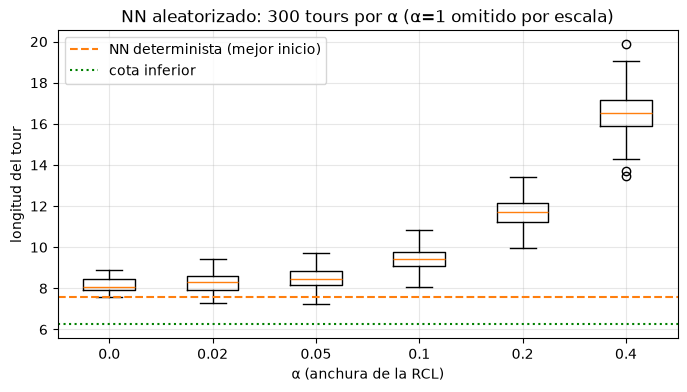

In [11]:
def nn_aleatorizado(D, alpha, rng, inicio=None):
    n = len(D); inicio = int(rng.integers(n)) if inicio is None else inicio
    visitado = np.zeros(n, bool); tour = [inicio]; visitado[inicio] = True
    for _ in range(n - 1):
        libres = np.flatnonzero(~visitado); d = D[tour[-1], libres]
        umbral = d.min() + alpha * (d.max() - d.min())
        cand = libres[d <= umbral + 1e-12]
        j = int(rng.choice(cand)); tour.append(j); visitado[j] = True
    return np.array(tour)

alphas = [0.0, 0.02, 0.05, 0.1, 0.2, 0.4, 1.0]
R = 300; res_alpha = {}
for a in alphas:
    r_ = np.random.default_rng(5)
    L = np.array([longitud_tour(D, nn_aleatorizado(D, a, r_)) for _ in range(R)])
    res_alpha[a] = L
print(f"cota inferior (Held-Karp): {lb:.3f}")
print(f"{'alpha':>6} {'media':>9} {'mejor':>9} {'desv.':>8} {'distintos':>10}   (gap de la mejor vs. cota)")
for a in alphas:
    L = res_alpha[a]
    print(f"{a:>6} {L.mean():9.3f} {L.min():9.3f} {L.std():8.3f} {len(np.unique(L.round(9))):>10}   {gap(L.min(), lb):6.2f} %")

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([res_alpha[a] for a in alphas[:-1]], tick_labels=[str(a) for a in alphas[:-1]])
ax.axhline(longitud_tour(D, t_nnm), color="C1", ls="--", label="NN determinista (mejor inicio)"); ax.axhline(lb, color="g", ls=":", label="cota inferior")
ax.set_xlabel("α (anchura de la RCL)"); ax.set_ylabel("longitud del tour"); ax.set_title(f"NN aleatorizado: {R} tours por α (α=1 omitido por escala)"); ax.legend(); plt.show()

Qué muestra la tabla (cifras impresas arriba):
- $\alpha=0$ es NN con inicio aleatorio: casi no hay diversidad (a lo sumo tantos tours distintos como ciudades de inicio).
- Con $\alpha$ **pequeño** (0.02–0.05) la media empeora un poco pero la **desviación crece** y, en el *mejor* de $R$ corridas, se supera a NN multi-inicio: se paga calidad media para ganar diversidad y cola favorable.
- Con $\alpha$ grande la calidad media se degrada rápido y el mejor-de-$R$ ya no compensa: se acerca al aleatorio (a $\alpha=1$ es exactamente el tour aleatorio).

Es el equilibrio calidad–diversidad que GRASP explota y que se calibra empíricamente: no existe un $\alpha$ universal.

## 10. *Iterated Greedy* (IG): destruir y reconstruir

Un constructivo se vuelve una **metaheurística de trayectoria** si, en vez de usarlo una vez, lo usamos *dentro de un bucle* sobre la solución actual (Ruiz & Stützle, 2007, para scheduling; la idea general es la de *ruin and recreate* / *Large Neighborhood Search*, ver notebook [04](04-vns-lns.ipynb)):

```
s ← constructivo()
s* ← s
repetir:
    s_parcial ← destruir(s, d)           # quitar d componentes (aleatorios o relacionados)
    s'        ← reconstruir(s_parcial)    # reinsertarlos con el criterio voraz
    si aceptar(s, s'):  s ← s'
    si f(s) < f(s*):    s* ← s
```

Para el TSP: **destruir** = sacar $d$ ciudades del tour; **reconstruir** = reinsertar cada una en su posición más barata (inserción más barata, en orden aleatorio). El criterio de aceptación puede ser "solo si no empeora" o un criterio tipo recocido con temperatura constante $T=\tau\cdot\bar{e}$ ($\bar e$ longitud media de arista de la solución inicial). Dos modos de destrucción: **aleatoria** y **relacionada** (sacar una ciudad y sus $d-1$ más cercanas, que crea un "hueco" local coherente; idea de Shaw, 1998).

La **fuerza de la destrucción** $d$ es el parámetro intensificación/diversificación: $d$ pequeño $\Rightarrow$ vecindario pequeño (intensifica); $d$ grande $\Rightarrow$ se reconstruye casi todo (diversifica y es caro).

inserción más barata: 7.766 -> IG (3000 iteraciones, d=4): 6.426  | cota: 6.241  | gap vs. cota: 2.96 %


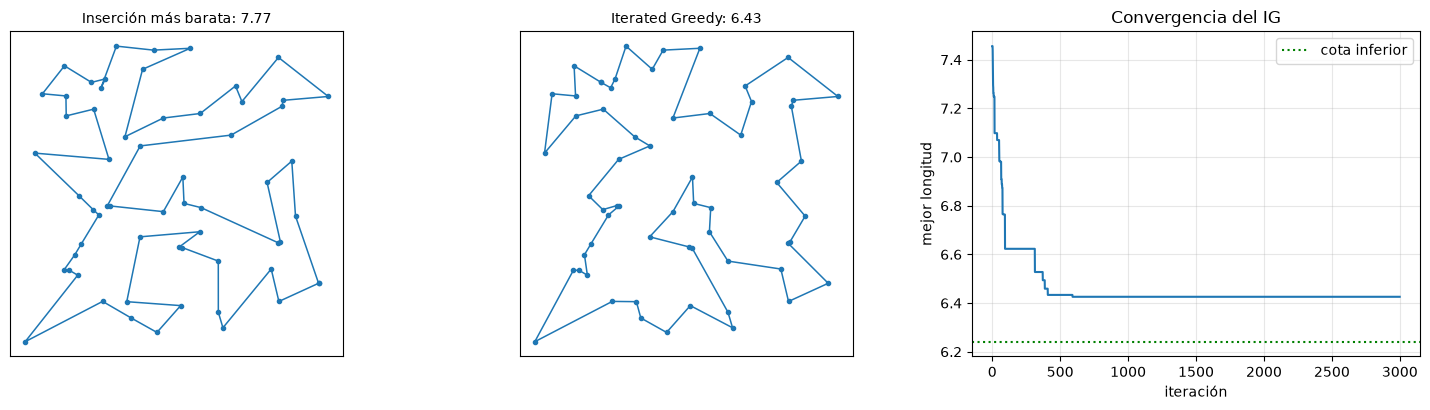

In [12]:
def reinsertar(D, parcial, quitados, rng):
    # Reinserta las ciudades 'quitados' (en orden aleatorio) en su posición más barata sobre el tour parcial.
    parcial = list(parcial); quitados = list(quitados); rng.shuffle(quitados)
    for k in quitados:
        T = np.array(parcial); Tn = np.roll(T, -1)
        c = D[T, k] + D[k, Tn] - D[T, Tn]
        parcial.insert(int(c.argmin()) + 1, int(k))
    return np.array(parcial)

def iterated_greedy_tsp(D, iters, d, tau, rng, destruccion="aleatoria", tour0=None):
    n = len(D)
    actual = insercion(D, "mas_barata", inicio=int(rng.integers(n))) if tour0 is None else tour0.copy()
    fa = longitud_tour(D, actual); mejor, fm = actual.copy(), fa
    Temp = tau * fa / n; traza = np.empty(iters)
    for it in range(iters):
        if destruccion == "aleatoria":
            quitados = rng.choice(actual, d, replace=False)
        else:                                               # relacionada: una ciudad y sus d-1 vecinas más cercanas
            semilla = int(rng.integers(n)); quitados = np.argsort(D[semilla])[:d]
        marca = np.zeros(n, bool); marca[quitados] = True
        parcial = actual[~marca[actual]]
        nuevo = reinsertar(D, parcial, quitados, rng); fn = longitud_tour(D, nuevo)
        if fn <= fa or (Temp > 0 and rng.random() < np.exp(-(fn - fa) / Temp)):
            actual, fa = nuevo, fn
            if fa < fm - 1e-12: mejor, fm = actual.copy(), fa
        traza[it] = fm
    assert es_permutacion(mejor, n) and abs(longitud_tour(D, mejor) - fm) < 1e-9
    return mejor, fm, traza

t_ig, f_ig, traza_ig = iterated_greedy_tsp(D, 3000, 4, 0.0, np.random.default_rng(0))
t_ins = insercion(D, "mas_barata")
print(f"inserción más barata: {longitud_tour(D, t_ins):.3f} -> IG (3000 iteraciones, d=4): {f_ig:.3f}  | cota: {lb:.3f}  | gap vs. cota: {gap(f_ig, lb):.2f} %")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
graficar_tour(pts, t_ins, axes[0], f"Inserción más barata: {longitud_tour(D, t_ins):.2f}")
graficar_tour(pts, t_ig, axes[1], f"Iterated Greedy: {f_ig:.2f}")
axes[2].plot(traza_ig); axes[2].axhline(lb, color="g", ls=":", label="cota inferior"); axes[2].set_xlabel("iteración"); axes[2].set_ylabel("mejor longitud"); axes[2].set_title("Convergencia del IG"); axes[2].legend()
plt.tight_layout(); plt.show()

### Efecto de la fuerza de destrucción, el modo y la aceptación
Comparamos con igual número de iteraciones (2000) y 4 semillas por configuración. Medimos el gap final respecto de la cota y el tiempo.

In [13]:
def correr_config(d, tau, modo, iters=2000, semillas=4):
    fs, t0 = [], time.perf_counter()
    for s in range(semillas):
        _, f, _ = iterated_greedy_tsp(D, iters, d, tau, np.random.default_rng(50 + s), modo)
        fs.append(f)
    return np.mean(fs), np.min(fs), (time.perf_counter() - t0) / semillas

print(f"cota inferior = {lb:.3f}")
print(f"{'d':>3} {'modo':>11} {'tau':>5} {'gap medio %':>12} {'gap mejor %':>12} {'s/corrida':>10}")
tabla_ig = []
for modo in ["aleatoria", "relacionada"]:
    for d in [2, 4, 8, 16]:
        m, b, t_ = correr_config(d, 0.0, modo)
        tabla_ig.append((modo, d, 0.0, gap(m, lb), gap(b, lb), t_))
        print(f"{d:>3} {modo:>11} {0.0:>5} {gap(m, lb):12.2f} {gap(b, lb):12.2f} {t_:10.2f}")
for tau in [0.02, 0.1, 0.5]:
    m, b, t_ = correr_config(4, tau, "relacionada")
    tabla_ig.append(("relacionada", 4, tau, gap(m, lb), gap(b, lb), t_))
    print(f"{4:>3} {'relacionada':>11} {tau:>5} {gap(m, lb):12.2f} {gap(b, lb):12.2f} {t_:10.2f}")

cota inferior = 6.241
  d        modo   tau  gap medio %  gap mejor %  s/corrida


  2   aleatoria   0.0         5.38         2.96       0.13


  4   aleatoria   0.0         3.87         2.80       0.19


  8   aleatoria   0.0         1.76         1.11       0.25


 16   aleatoria   0.0         1.71         1.11       0.54


...

  8 relacionada   0.0         1.92         1.11       0.28


 16 relacionada   0.0         1.30         1.11       0.53


  4 relacionada  0.02         2.56         1.49       0.20


  4 relacionada   0.1         2.05         1.11       0.15


  4 relacionada   0.5         1.71         1.11       0.18


Lo que muestran los números (todas las configuraciones usan 2000 iteraciones):
- **El IG mejora mucho a su propio constructivo inicial**: el gap contra la cota pasa de decenas de puntos porcentuales (inserción más barata) a pocos puntos, en menos de un segundo por corrida.
- **Fuerza de destrucción $d$:** con $d$ pequeño el gap medio es peor (se estanca en óptimos locales del vecindario "quitar-y-reinsertar $d$"); al subir $d$ mejora, pero el tiempo por corrida crece casi linealmente con $d$. Hay una relación **calidad-tiempo**, no una $d$ gratis.
- **Modo relacionado vs. aleatorio:** con $d$ pequeño, sacar ciudades *cercanas entre sí* rinde mejor que sacarlas al azar (porque re-optimiza una región coherente); a $d$ grande la diferencia se reduce o incluso se invierte según la configuración (mira $d=8$).
- **Aceptación con temperatura** ($\tau>0$): a $d=4$, una temperatura muy baja ($\tau=0.02$) casi no cambia nada, pero valores mayores ($\tau=0.1$, $0.5$) mejoran el gap medio respecto de "solo mejora": diversificar ayuda cuando el vecindario es chico.
- Varias configuraciones coinciden en el mismo mejor valor: es probable (no seguro) que esté muy cerca del óptimo, y que el gap residual contra la cota sea en gran parte **holgura de la cota**.

**Limitación importante.** El IG puro reconstruye solo con inserciones; el tour final **no** es necesariamente un óptimo local respecto de 2-opt. Combinar IG con búsqueda local (ver [03 · Búsqueda local e ILS](03-busqueda-local-ils.ipynb)) es la receta habitual y mejora de manera notable los resultados.

## 11. Un constructivo para el QAP

En el QAP los "componentes" son pares *(instalación, ubicación)*. Un constructivo voraz típico se apoya en dos observaciones: las instalaciones con **mucho flujo total** deben ir en ubicaciones **céntricas** (poca distancia total al resto).

```
ordenar instalaciones por flujo total (decreciente)  |  ubicaciones por centralidad (creciente en suma de distancias)
colocar la primera instalación en la ubicación más central
para cada instalación i siguiente:
    para cada ubicación libre l:
        costo(i, l) = Σ_{j ya colocada} [ F_ij · D_{l,p(j)} + F_ji · D_{p(j),l} ]
    asignar i a argmin_l costo(i, l)
```

Variante **dinámica**: en lugar de un orden fijo, elegir en cada paso la instalación **con mayor flujo hacia las ya colocadas**. Ambas se pueden aleatorizar con RCL igual que antes. Como cota inferior barata usamos la **cota de reordenamiento**: por la desigualdad del reordenamiento, emparejar los flujos fuera de la diagonal (orden decreciente) con las distancias fuera de la diagonal (orden creciente) da un valor $\le f^\star$ (es floja, pero válida; la cota de Gilmore–Lawler es más ajustada).

In [14]:
def crear_qap(n, rng):
    F = rng.integers(0, 10, (n, n)); F = np.triu(F, 1); F = F + F.T
    pts = rng.random((n, 2)); D = cdist(pts, pts)
    return F.astype(float), D

def costo_qap(F, D, p):
    p = np.asarray(p)
    return (F * D[np.ix_(p, p)]).sum()

def cota_reordenamiento(F, D):
    n = len(F); m = ~np.eye(n, dtype=bool)
    f = np.sort(F[m])[::-1]; d = np.sort(D[m])
    return float(f @ d)

def qap_voraz(F, D, orden="fijo", alpha=0.0, rng=None):
    # Constructivo voraz para QAP. orden in {"fijo", "dinamico"}; alpha>0 => RCL aleatorizada.
    rng = rng or np.random.default_rng(0)
    n = len(F); flujo = F.sum(0) + F.sum(1); central = D.sum(0) + D.sum(1)
    p = -np.ones(n, int); libres = np.ones(n, bool); sin_asignar = np.ones(n, bool); acum = 0.0
    primera = int(np.argmax(flujo)); loc0 = int(np.argmin(central))
    p[primera] = loc0; libres[loc0] = False; sin_asignar[primera] = False
    for _ in range(n - 1):
        asig = np.flatnonzero(p >= 0)
        if orden == "fijo":
            i = int(np.flatnonzero(sin_asignar)[np.argmax(flujo[sin_asignar])])
        else:
            sc = np.where(sin_asignar, (F[:, asig] + F[asig, :].T).sum(1) + 1e-6 * flujo, -np.inf); i = int(sc.argmax())
        L = np.flatnonzero(libres); pa = p[asig]
        c = D[np.ix_(L, pa)] @ F[i, asig] + D[np.ix_(pa, L)].T @ F[asig, i]        # costo incremental de colocar i en cada ubicación libre
        umbral = c.min() + alpha * (c.max() - c.min())
        a = int(rng.choice(np.flatnonzero(c <= umbral + 1e-12)))
        p[i] = L[a]; libres[L[a]] = False; sin_asignar[i] = False; acum += c[a]
    assert es_permutacion(p, n) and abs(acum - costo_qap(F, D, p)) < 1e-8          # costo incremental == recomputación
    return p

# Verificación de la cota de reordenamiento contra el óptimo exacto (n=8, enumeración)
F8, D8 = crear_qap(8, np.random.default_rng(77))
opt8 = min(costo_qap(F8, D8, np.array(q)) for q in itertools.permutations(range(8)))
print(f"n=8: óptimo exacto={opt8:.3f}  cota de reordenamiento={cota_reordenamiento(F8, D8):.3f}  voraz fijo={costo_qap(F8, D8, qap_voraz(F8, D8)):.3f}  voraz dinámico={costo_qap(F8, D8, qap_voraz(F8, D8, 'dinamico')):.3f}")
assert cota_reordenamiento(F8, D8) <= opt8 + 1e-9

n=8: óptimo exacto=129.437  cota de reordenamiento=116.093  voraz fijo=158.370  voraz dinámico=146.302


Igual que en el TSP, podemos envolver el constructivo en un **Iterated Greedy**: destruir $d$ instalaciones (liberar sus ubicaciones) y reasignarlas, cada una a la ubicación libre de menor costo incremental respecto de las que siguen colocadas.

In [15]:
def iterated_greedy_qap(F, D, iters, d, tau, rng):
    n = len(F); p = qap_voraz(F, D, "dinamico"); fa = costo_qap(F, D, p)
    mejor, fm = p.copy(), fa; Temp = tau * fa / n
    for it in range(iters):
        quitadas = rng.choice(n, d, replace=False)
        q = p.copy(); q[quitadas] = -1
        libres = np.ones(n, bool); libres[q[q >= 0]] = False
        for i in rng.permutation(quitadas):
            asig = np.flatnonzero(q >= 0); L = np.flatnonzero(libres); pa = q[asig]
            c = D[np.ix_(L, pa)] @ F[i, asig] + D[np.ix_(pa, L)].T @ F[asig, i]
            a = int(c.argmin()); q[i] = L[a]; libres[L[a]] = False
        fn = costo_qap(F, D, q)
        if fn <= fa or (Temp > 0 and rng.random() < np.exp(-(fn - fa) / Temp)):
            p, fa = q, fn
            if fa < fm - 1e-12: mejor, fm = p.copy(), fa
    assert es_permutacion(mejor, n) and abs(costo_qap(F, D, mejor) - fm) < 1e-8
    return mejor, fm

NQ, NINSTQ = 20, 10
filasq = []
for s in range(NINSTQ):
    Fq, Dq = crear_qap(NQ, np.random.default_rng(500 + s)); rq = np.random.default_rng(s)
    aleat = np.array([costo_qap(Fq, Dq, rq.permutation(NQ)) for _ in range(1000)])
    v_fijo = costo_qap(Fq, Dq, qap_voraz(Fq, Dq, "fijo")); v_din = costo_qap(Fq, Dq, qap_voraz(Fq, Dq, "dinamico"))
    v_rcl = min(costo_qap(Fq, Dq, qap_voraz(Fq, Dq, "dinamico", 0.3, rq)) for _ in range(200))
    _, v_ig = iterated_greedy_qap(Fq, Dq, 1500, 3, 0.05, rq)
    res_q = {"Aleatorio (media)": aleat.mean(), "Mejor de 1000 aleatorios": aleat.min(), "Voraz (orden fijo)": v_fijo,
             "Voraz (dinámico)": v_din, "Voraz RCL α=0.3 (mejor de 200)": v_rcl, "Iterated Greedy (1500 it.)": v_ig}
    ref = min(res_q.values()); lbq = cota_reordenamiento(Fq, Dq)
    for k, v in res_q.items():
        filasq.append(dict(instancia=s, metodo=k, gap_mejor_conocido=gap(v, ref), gap_cota=gap(v, lbq)))
dfq = pd.DataFrame(filasq)
print(f"QAP n={NQ}, {NINSTQ} instancias. Gap (%) vs. mejor valor conocido (de los métodos comparados) y vs. cota de reordenamiento")
print(dfq.groupby("metodo", sort=False)[["gap_mejor_conocido", "gap_cota"]].mean().round(2).to_string())

QAP n=20, 10 instancias. Gap (%) vs. mejor valor conocido (de los métodos comparados) y vs. cota de reordenamiento
                                gap_mejor_conocido  gap_cota
metodo                                                      
Aleatorio (media)                            15.08     41.44
Mejor de 1000 aleatorios                      7.57     32.21
Voraz (orden fijo)                            7.07     31.59
Voraz (dinámico)                              6.15     30.47
Voraz RCL α=0.3 (mejor de 200)                2.84     26.38
Iterated Greedy (1500 it.)                    0.00     22.91


En el QAP (gap contra el mejor valor conocido, que aquí es el mejor de los métodos comparados; y contra la cota de reordenamiento, que es débil):
- Los voraces superan a la media aleatoria por un margen amplio y rinden de forma similar al *mejor de 1000 aleatorios* con un costo mucho menor; la variante **dinámica** es ligeramente mejor que la de orden fijo.
- La aleatorización con RCL (mejor de 200) mejora claramente al voraz determinista, y el **Iterated Greedy** es el mejor de todos con diferencia (su gap es 0 porque define el mejor conocido en estas instancias).
- La **cota de reordenamiento** deja un gap de decenas de puntos porcentuales incluso para el mejor método: es válida pero floja, por eso para el QAP se prefiere reportar contra el mejor valor conocido o cotas más fuertes (Gilmore–Lawler y posteriores).
- Para el QAP, los constructivos quedan lejos de lo alcanzable: son un buen punto de partida para la búsqueda local, tema de la siguiente notebook.

## 12. Ventajas y limitaciones

| | Constructivos puros | Constructivos aleatorizados | Iterated Greedy |
|---|---|---|---|
| Costo | Muy bajo | Bajo por muestra | Moderado (varias reconstrucciones) |
| Calidad | Media; fija | Variable; mejor-de-$R$ mejora | Mejor; mejora con iteraciones |
| Diversidad | Ninguna | Controlada por $\alpha$ | Controlada por $d$ y la aceptación |
| Riesgo | Malas decisiones tempranas irreversibles | Muchas muestras para ganar poco | No es óptimo local respecto de 2-opt |
| Uso típico | Solución inicial, línea base | GRASP, multi-inicio | Metaheurística autónoma o con búsqueda local |

## Resumen

- Un constructivo construye una solución componente a componente con un criterio voraz; es rápido, pero sin garantías y sin corregir errores tempranos.
- Para TSP comparamos NN, tres inserciones, greedy de aristas y ahorros; el ranking real se mide contra una **cota inferior** (1-tree con ascenso de Held–Karp), no contra un óptimo desconocido. Todas las cotas y los costos incrementales se verificaron contra recomputación/óptimo exacto.
- La **aleatorización** (RCL con parámetro $\alpha$) convierte un constructivo en un generador de soluciones diversas.
- **Iterated Greedy** = destruir + reconstruir + aceptar: es una metaheurística de trayectoria; $d$ y el criterio de aceptación regulan intensificación/diversificación.
- El mismo esquema aplica al QAP con un constructivo propio.

## Ejercicios propuestos

1. **Doble árbol.** Implementa la 2-aproximación basada en MST (recorrido en preorden del MST con atajos) y compárala con las demás. ¿Qué gap obtiene?
2. **Ahorros con otro depósito.** En `ahorros_cw`, prueba depósitos distintos (el más lejano, uno aleatorio). ¿Cuánto cambia el gap? ¿Por qué el depósito central es una buena opción?
3. **Inserción más lejana con RCL.** Aleatoriza la elección de la ciudad (entre las $\alpha$-mejores) y analiza la distribución de resultados como en la sección 9.
4. **Método piloto.** Para cada candidato en NN, completa el tour con NN y elige el candidato cuyo tour completo sea más corto (Duin & Voß, 1999). Mide mejora y costo.
5. **IG con búsqueda local.** Tras cada reconstrucción aplica un 2-opt rápido (ver notebook 03). Compara con el IG puro a igual tiempo.
6. **QAP.** Implementa una versión del constructivo que elija la *ubicación* según centralidad y la *instalación* por mayor costo incremental simultáneamente. ¿Mejora al voraz dinámico?
7. **Cota.** Mide cuánto sube la cota de Held–Karp al aumentar `iters` de 120 a 600. ¿Cuándo deja de mejorar?

## Referencias

- Rosenkrantz, D. J., Stearns, R. E. & Lewis, P. M. (1977). An analysis of several heuristics for the traveling salesman problem. *SIAM Journal on Computing*, 6(3).
- Clarke, G. & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research*, 12(4).
- Johnson, D. S. & McGeoch, L. A. (1997). The traveling salesman problem: a case study in local optimization. En *Local Search in Combinatorial Optimization*, Wiley.
- Held, M. & Karp, R. M. (1970). The traveling-salesman problem and minimum spanning trees. *Operations Research*, 18(6).
- Held, M. & Karp, R. M. (1971). The traveling-salesman problem and minimum spanning trees: Part II. *Mathematical Programming*, 1.
- Ruiz, R. & Stützle, T. (2007). A simple and effective iterated greedy algorithm for the permutation flowshop scheduling problem. *European Journal of Operational Research*, 177(3).
- Shaw, P. (1998). Using constraint programming and local search methods to solve vehicle routing problems. *Principles and Practice of Constraint Programming (CP 1998)*.
- Feo, T. A. & Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6.
- Duin, C. & Voß, S. (1999). The pilot method: a strategy for heuristic repetition with application to the Steiner problem in graphs. *Networks*, 34(3).
- Koopmans, T. C. & Beckmann, M. (1957). Assignment problems and the location of economic activities. *Econometrica*, 25(1).
- Gilmore, P. C. (1962). Optimal and suboptimal algorithms for the quadratic assignment problem. *Journal of the SIAM*, 10(2).